In [1]:
import anndata as ad
import re
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
from scipy import sparse
from scib_metrics.nearest_neighbors import pynndescent
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import os
from tqdm.notebook import tqdm

spatial_dir = '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/'
spatial_files = sorted([os.path.join(spatial_dir,f) for f in os.listdir(spatial_dir) if f.startswith('GSM') and f.endswith('rctd_annotated_val_med_with_admix_probs.h5ad')])
ad_list = []
print(spatial_files)
for f in tqdm(spatial_files):
    pass
    subset = ad.read_h5ad(f)
    subset = subset[subset.obs.groupby(['harmony_cell_type']).sample(frac=0.05).index].copy()
    subset.obs['source_file'] = f
    ad_list.append(subset)

ad_list

# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# sc_data = ad.concat([ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_val_med_with_admix_probs.h5ad'),
#                     ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')],
#                     join='outer')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_100th_train_med_with_admix_probs.h5ad')

# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_val_med_with_admix_probs.h5ad')

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: 

['/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509156_breast_breast_B17_B17_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509157_breast_breast_B16_B16_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509158_breast_breast_B15_B15_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509159_breast_breast_B14_B14_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509160_breast_breast_B2_B2_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509161_breast_breast_B13_B13_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509162_breast_breast_B12_B12_rctd_annotated_val_med_with_admix_probs.h5ad', '/compu

  0%|          | 0/19 [00:00<?, ?it/s]

/tmp/ipykernel_2844315/3255042750.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  subset = subset[subset.obs.groupby(['harmony_cell_type']).sample(frac=0.05).index].copy()
/tmp/ipykernel_2844315/3255042750.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  subset = subset[subset.obs.groupby(['harmony_cell_type']).sample(frac=0.05).index].copy()
/tmp/ipykernel_2844315/3255042750.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence

[AnnData object with n_obs × n_vars = 3409 × 277
     obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split', 'has_split_purified_counts', 'source_file'
     var: 'feature_name', 'feature_type', 'genome', 'id', 'name', 'feature'
     uns: 'cell_type_dict', 'gene_mapping:ensembl_to_symbol', 'neighbor_celltype_dict', 'neighbor_dict', 'rctd_cell_type_names', 'rctd_class_df', '

In [2]:
sc_data = ad.concat(ad_list,join='outer')
sc_data = sc_data[sc_data.obs['harmony_cell_type']!='malignant cell']

View of AnnData object with n_obs × n_vars = 45214 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split', 'has_split_purified_counts', 'source_file'
    obsm: 'X_pca_harmony', 'X_pca_harmony_GSM9509156_breast_breast_B17_B17_rctd', 'rctd_weights', 'rctd_weights_doublet', 'X_pca_harmony_GSM9509157_breast_breast_B16_B16_rctd', 'X_pca_harmony_GSM9509158_breast_breast

['/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509156_breast_breast_B17_B17_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509157_breast_breast_B16_B16_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509158_breast_breast_B15_B15_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509159_breast_breast_B14_B14_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509160_breast_breast_B2_B2_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509161_breast_breast_B13_B13_rctd_annotated_val_med_with_admix_probs.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509162_breast_breast_B12_B12_rctd_annotated_val_med_with_admix_probs.h5ad', '/compu

<Axes: ylabel='Count'>

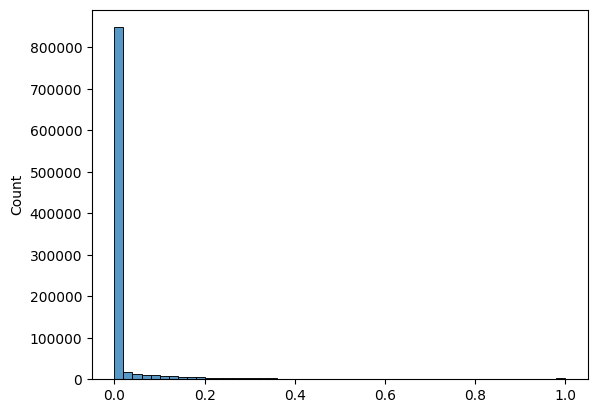

In [4]:
import seaborn as sns
source_files = sc_data.obs['source_file'].unique().tolist()
print(source_files)

sns.histplot(sc_data[sc_data.obs['source_file']==source_files[-1]].layers['admix_probs'].toarray().flatten(),bins=50)

In [5]:
count_vals = np.unique(sc_data.X.toarray().flatten())
count_vals.sort()
print(count_vals)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  87  88  89  90
  91  92  93  95  99 101 104 108 117 118 181]


In [6]:
from tqdm.notebook import tqdm
tissue_key = 'source_file'
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
tissues

['/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509156_breast_breast_B17_B17_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509157_breast_breast_B16_B16_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509158_breast_breast_B15_B15_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509159_breast_breast_B14_B14_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509160_breast_breast_B2_B2_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509161_breast_breast_B13_B13_rctd_annotated_val_med_with_admix_probs.h5ad',
 '/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509162_breast_breast_B12_B12_rctd_annotated_val_med_with_admix_probs.h5ad',
 

In [ ]:
# sc_data.layers['admix_probs'] = sc_data.layers['admix_probs'].toarray()
sc_data.X = np.nan_to_num(sc_data.X)

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/anndata.py:616: FutureWarning: You are attempting to set `X` to a matrix on a view which has non-unique indices. The resulting `adata.X` will likely not equal the value to which you set it. To avoid this potential issue, please make a copy of the data first. In the future, this operation will throw an error.
  warnings.warn(msg, FutureWarning, stacklevel=1)


In [ ]:
label_key = 'harmony_cell_type'
tissue_key = 'source_file'
target_removed_fractions = [0.01, 0.02, 0.05, 0.1, 0.2]
prob_thresholds = [0.95, 0.9, 0.85, 0.8, 0.6, 0.4, 0.2]
leiden_resolution = 1.0
leiden_optimize_resolution = False
leiden_n_neighbors = 15
n_pcs = 50
library_size_target_sum = 1e4
n_jobs = 1
random_state = 0

additional_counts_layer_key = 'split_purified_counts'  # e.g. 'my_counts_layer'
additional_counts_case_label = 'SPLIT'  # e.g. 'my_counts'; defaults to additional_counts_layer_key
additional_counts_zero_high_prob = False

def counts_from_layer(adata, layer_key=None):
    if layer_key is None:
        return adata.X
    if layer_key not in adata.layers:
        raise KeyError(f"Layer {layer_key!r} not found in adata.layers.")
    return adata.layers[layer_key]

def cleaned_counts(X, admix_probs, thresh):
    if sparse.issparse(X):
        cleaned = X.copy()
        row_idx, col_idx = cleaned.nonzero()
        probs_for_nonzero_counts = admix_probs[row_idx, col_idx]
        cleaned.data[np.asarray(probs_for_nonzero_counts).ravel() >= thresh] = 0
        cleaned.eliminate_zeros()
        return cleaned

    if sparse.issparse(admix_probs):
        admix_probs = admix_probs.toarray()

    return np.where(admix_probs >= thresh, 0, X)


def cleaned_admixed_counts(adata, thresh):
    return cleaned_counts(adata.X, adata.layers["admix_probs"], thresh)

import numpy as np
from scipy import sparse

def threshold_for_removed_fraction(probs, X, target_removed_frac: float):
    """
    Choose thr so that removing entries with probs >= thr removes ~target_removed_frac
    of TOTAL transcript counts (sum of counts), considering only X>0 entries.

    Returns
    -------
    thr : float
    achieved : float  (fraction of transcript counts removed using probs >= thr)
    """
    r = float(target_removed_frac)
    r = min(max(r, 0.0), 1.0)
    if r == 0.0:
        return np.inf, 0.0
    if r == 1.0:
        return -np.inf, 1.0

    # Pull (pvals, counts) only where X>0
    if sparse.issparse(X):
        Xcoo = X.tocoo()
        counts = Xcoo.data.astype(float)
        pvals = np.asarray(probs[Xcoo.row, Xcoo.col]).ravel().astype(float)
    else:
        X = np.asarray(X)
        probs = np.asarray(probs)
        nz = X > 0
        counts = X[nz].astype(float)
        pvals = probs[nz].astype(float)

    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    pvals = pvals[good]
    counts = counts[good]
    if counts.size == 0:
        raise ValueError("No expressed transcripts found (X>0).")

    total = float(counts.sum())
    target = r * total

    # Sort by probability descending, accumulate transcript counts
    order = np.argsort(pvals)[::-1]
    p_sorted = pvals[order]
    c_sorted = counts[order]
    cum = np.cumsum(c_sorted)

    idx = int(np.searchsorted(cum, target, side="left"))
    idx = min(idx, len(p_sorted) - 1)
    thr = float(p_sorted[idx])

    # Achieved fraction if you remove probs >= thr (important!)
    removed = float(c_sorted[p_sorted >= thr].sum())
    achieved = removed / total

    return thr, achieved

def _prepare_matrix_and_labels(X, labels, make_dense=False):
    labels = pd.Series(labels).astype('category')
    valid = ~labels.isna().to_numpy()
    X = X[valid]
    labels = labels[valid].cat.remove_unused_categories()
    if make_dense and sparse.issparse(X):
        X = X.toarray()
    return X, labels.to_numpy()


def _obsm_key_for_case(case_name):
    safe_case_name = re.sub(r'[^0-9A-Za-z_]+', '_', case_name).strip('_')
    return f'X_pca_metric_{safe_case_name}'


def _store_preprocessed_pcs(adata, obs_names, obsm_key, X_preprocessed):
    if obsm_key not in adata.obsm:
        adata.obsm[obsm_key] = np.full((adata.n_obs, n_pcs), np.nan, dtype=np.float32)
    row_idx = adata.obs_names.get_indexer(obs_names)
    if np.any(row_idx < 0):
        missing = obs_names[row_idx < 0].tolist()
        raise KeyError(f'Observations missing from result AnnData: {missing[:5]}')
    stored = adata.obsm[obsm_key]
    stored[row_idx, : X_preprocessed.shape[1]] = X_preprocessed.astype(np.float32, copy=False)
    adata.obsm[obsm_key] = stored


def preprocess_counts_for_metrics(X):
    adata = ad.AnnData(X=X.copy())
    sc.pp.normalize_total(adata, target_sum=library_size_target_sum)
    sc.pp.log1p(adata)
    n_comps = min(n_pcs, adata.n_obs - 1, adata.n_vars - 1)
    if n_comps < 1:
        raise ValueError('PCA metrics require at least two observations and two variables.')
    sc.pp.pca(adata, n_comps=n_comps, random_state=random_state)
    return adata.obsm['X_pca']


def _neighbors_for_scib_leiden_metrics(embedding):
    neighbors = pynndescent(
        embedding,
        n_neighbors=min(leiden_n_neighbors, embedding.shape[0]),
        random_state=random_state,
        n_jobs=n_jobs,
    )
    return neighbors


def cleaned_admixed_counts(adata, thresh):
    admixed = adata.X #+ adata.layers['admixed_counts']
    admix_probs = adata.layers['admix_probs']

    if sparse.issparse(admixed):
        cleaned = admixed.copy()
        row_idx, col_idx = cleaned.nonzero()
        probs_for_nonzero_counts = admix_probs[row_idx, col_idx]
        cleaned.data[np.asarray(probs_for_nonzero_counts).ravel() >= thresh] = 0
        cleaned.eliminate_zeros()
        return cleaned

    if sparse.issparse(admix_probs):
        admix_probs = admix_probs.toarray()

    return np.where(admix_probs >= thresh, 0, admixed)


def score_case(
    tissue,
    case_name,
    X,
    labels,
    result_adata,
    target_removed_fraction=np.nan,
    threshold=np.nan,
    achieved_removed_fraction=np.nan,
):
    valid_obs_names = pd.Index(labels.index)[~pd.Series(labels).isna().to_numpy()]
    X_raw, labels_prepared = _prepare_matrix_and_labels(X, labels)
    X_preprocessed = preprocess_counts_for_metrics(X_raw)
    obsm_key = _obsm_key_for_case(case_name)
    _store_preprocessed_pcs(result_adata, valid_obs_names, obsm_key, X_preprocessed)
    neighbors = _neighbors_for_scib_leiden_metrics(X_preprocessed)
    leiden_metrics = scib_metrics.nmi_ari_cluster_labels_leiden(
        neighbors,
        labels_prepared,
        optimize_resolution=leiden_optimize_resolution,
        resolution=leiden_resolution,
        n_jobs=n_jobs,
        seed=random_state,
    )
    return {
        'tissue': tissue,
        'case': case_name,
        'obsm_key': obsm_key,
        'target_removed_fraction': target_removed_fraction,
        'admix_prob_threshold': threshold,
        'achieved_removed_fraction': achieved_removed_fraction,
        'silhouette_score': silhouette_score(X_preprocessed, labels_prepared, metric='cosine'),
        'calinski_harabasz': calinski_harabasz_score(X_preprocessed, labels_prepared),
        'davies_bouldin': davies_bouldin_score(X_preprocessed, labels_prepared),
        'leiden_nmi_vs_cell_type': leiden_metrics['nmi'],
        'leiden_adjusted_rand_vs_cell_type': leiden_metrics['ari'],
    }


def score_tissue(tissue, adata, result_adata):
    rows = [
        score_case(tissue, "admixed", adata.X, adata.obs[label_key], result_adata),
    ]

    for target_removed_fraction in target_removed_fractions:
        thresh, achieved_removed_fraction = threshold_for_removed_fraction(
            adata.layers["admix_probs"],
            adata.X,
            target_removed_fraction,
        )
        rows.append(
            score_case(
                tissue,
                f"cleaned_admixed_removed_frac_{target_removed_fraction:g}",
                cleaned_admixed_counts(adata, thresh),
                adata.obs[label_key],
                result_adata,
                target_removed_fraction=target_removed_fraction,
                threshold=thresh,
                achieved_removed_fraction=achieved_removed_fraction,
            )
        )

    if additional_counts_layer_key is not None:
        additional_counts = counts_from_layer(adata, additional_counts_layer_key)
        additional_case_label = additional_counts_case_label or additional_counts_layer_key

        rows.append(
            score_case(
                tissue,
                additional_case_label,
                additional_counts,
                adata.obs[label_key],
                result_adata,
            )
        )

        if additional_counts_zero_high_prob:
            for target_removed_fraction in target_removed_fractions:
                thresh, achieved_removed_fraction = threshold_for_removed_fraction(
                    adata.layers["admix_probs"],
                    additional_counts,
                    target_removed_fraction,
                )
                rows.append(
                    score_case(
                        tissue,
                        f"{additional_case_label}_removed_frac_{target_removed_fraction:g}",
                        cleaned_counts(additional_counts, adata.layers["admix_probs"], thresh),
                        adata.obs[label_key],
                        result_adata,
                        target_removed_fraction=target_removed_fraction,
                        threshold=thresh,
                        achieved_removed_fraction=achieved_removed_fraction,
                    )
                )

    return rows


metrics_adata = sc_data
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
metric_rows = []
for tissue in tqdm(tissues):
    print(tissue)
    tissue_data = sc_data[sc_data.obs[tissue_key] == tissue].copy()
    metric_rows.extend(score_tissue(tissue, tissue_data, metrics_adata))

cell_type_separation = pd.DataFrame(metric_rows)
metrics_adata.uns['cell_type_separation_metrics'] = cell_type_separation

metrics_adata

  0%|          | 0/19 [00:00<?, ?it/s]

/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509156_breast_breast_B17_B17_rctd_annotated_val_med_with_admix_probs.h5ad


/tmp/ipykernel_2844315/2651884700.py:115: ImplicitModificationWarning: Setting element `.obsm['X_pca_metric_admixed']` of view, initializing view as actual.
  adata.obsm[obsm_key] = np.full((adata.n_obs, n_pcs), np.nan, dtype=np.float32)


/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509157_breast_breast_B16_B16_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509158_breast_breast_B15_B15_rctd_annotated_val_med_with_admix_probs.h5ad


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509159_breast_breast_B14_B14_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509160_breast_breast_B2_B2_rctd_annotated_val_med_with_admix_probs.h5ad


... (7 outputs left out)

/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509169_breast_breast_B6_B6_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509170_breast_breast_B3_B3_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509171_breast_breast_B5_B5_rctd_annotated_val_med_with_admix_probs.h5ad


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509172_breast_breast_B1_B1_1_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509173_breast_breast_B1_B1_2_rctd_annotated_val_med_with_admix_probs.h5ad
/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509174_breast_breast_B1_B1_3_rctd_annotated_val_med_with_admix_probs.h5ad


AnnData object with n_obs × n_vars = 45214 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split', 'has_split_purified_counts', 'source_file'
    uns: 'cell_type_separation_metrics'
    obsm: 'X_pca_harmony', 'X_pca_harmony_GSM9509156_breast_breast_B17_B17_rctd', 'rctd_weights', 'rctd_weights_doublet', 'X_pca_harmony_GSM9509157_breast_breast_B16_B16_rctd', 'X_pca_

In [ ]:
cell_type_separation['filename'] = cell_type_separation['tissue'].copy()
cell_type_separation['tissue'] = cell_type_separation['filename'].apply(lambda x: "_".join(x.split('/')[-1].split('_')[:-7][3:]))
# cell_type_separation['tissue_short'] = cell_type_separation['filename'].apply(lambda x: "_".join(x.split('/')[-1]))
cell_type_separation

,tissue,case,obsm_key,target_removed_fraction,admix_prob_threshold,achieved_removed_fraction,silhouette_score,calinski_harabasz,davies_bouldin,leiden_nmi_vs_cell_type,leiden_adjusted_rand_vs_cell_type,filename
0,B17_B17,admixed,X_pca_metric_admixed,NaN,NaN,NaN,-0.018412,30.260747,6.738092,0.295106,0.188385,/compute/oven-0-13/jwinchel/spatial_adata/heim...
1,B17_B17,cleaned_admixed_removed_frac_0.01,X_pca_metric_cleaned_admixed_removed_frac_0_01,0.01,0.987330,0.010006,-0.018442,30.622810,6.761252,0.299867,0.197740,/compute/oven-0-13/jwinchel/spatial_adata/heim...
2,B17_B17,cleaned_admixed_removed_frac_0.02,X_pca_metric_cleaned_admixed_removed_frac_0_02,0.02,0.966912,0.020027,-0.018179,30.962941,6.847410,0.298295,0.194459,/compute/oven-0-13/jwinchel/spatial_adata/heim...
3,B17_B17,cleaned_admixed_removed_frac_0.05,X_pca_metric_cleaned_admixed_removed_frac_0_05,0.05,0.859460,0.050043,-0.017036,31.705424,7.016462,0.292101,0.180344,/compute/oven-0-13/jwinchel/spatial_adata/heim...
4,B17_B17,cleaned_admixed_removed_frac_0.1,X_pca_metric_cleaned_admixed_removed_frac_0_1,0.10,0.628829,0.100004,-0.014297,32.616222,6.989969,0.303327,0.209615,/compute/oven-0-13/jwinchel/spatial_adata/heim...
...,...,...,...,...,...,...,...,...,...,...,...,...
128,B1_B1_3,cleaned_admixed_removed_frac_0.02,X_pca_metric_cleaned_admixed_removed_frac_0_02,0.02,0.968664,0.020004,0.035625,90.446857,6.355552,0.469207,0.322002,/compute/oven-0-13/jwinchel/spatial_adata/heim...
129,B1_B1_3,cleaned_admixed_removed_frac_0.05,X_pca_metric_cleaned_admixed_removed_frac_0_05,0.05,0.849474,0.050008,0.034451,91.329793,6.393972,0.464258,0.331044,/compute/oven-0-13/jwinchel/spatial_adata/heim...
130,B1_B1_3,cleaned_admixed_removed_frac_0.1,X_pca_metric_cleaned_admixed_removed_frac_0_1,0.10,0.596058,0.100001,0.032124,92.168994,6.514010,0.458768,0.306963,/compute/oven-0-13/jwinchel/spatial_adata/heim...
131,B1_B1_3,cleaned_admixed_removed_frac_0.2,X_pca_metric_cleaned_admixed_removed_frac_0_2,0.20,0.289870,0.200001,0.028126,93.748609,6.440239,0.433711,0.289634,/compute/oven-0-13/jwinchel/spatial_adata/heim...


/tmp/ipykernel_2844315/3727878686.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')


[Text(0, 0, 'X_pca_metric_admixed'),
 Text(1, 0, 'X_pca_metric_cleaned_admixed_removed_frac_0_01'),
 Text(2, 0, 'X_pca_metric_cleaned_admixed_removed_frac_0_02'),
 Text(3, 0, 'X_pca_metric_cleaned_admixed_removed_frac_0_05'),
 Text(4, 0, 'X_pca_metric_cleaned_admixed_removed_frac_0_1'),
 Text(5, 0, 'X_pca_metric_cleaned_admixed_removed_frac_0_2'),
 Text(6, 0, 'X_pca_metric_SPLIT')]

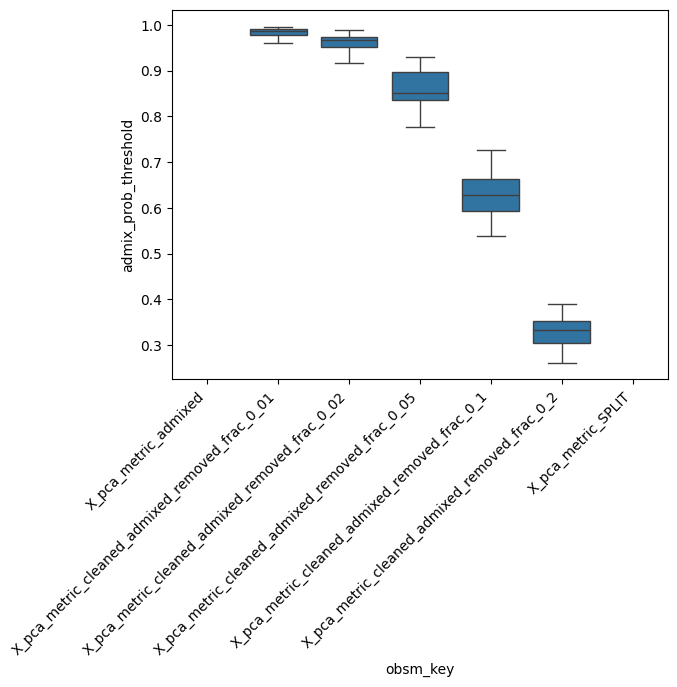

In [15]:
ax = sns.boxplot(data=cell_type_separation,x='obsm_key',y='admix_prob_threshold',showfliers=True)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')

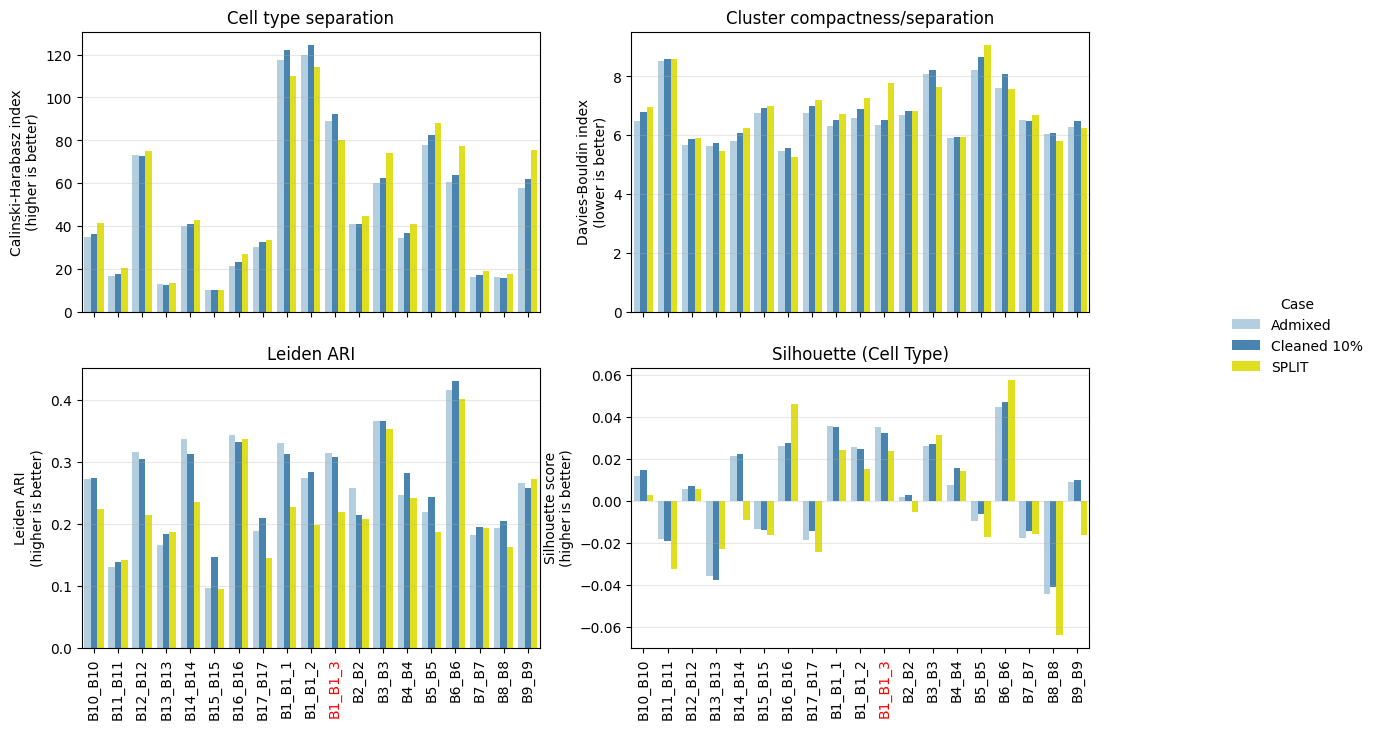

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

case_order = [
    "admixed",
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    "cleaned_admixed_removed_frac_0.1",
    # "cleaned_admixed_removed_frac_0.2",
    "SPLIT",
]

case_labels = {
    "admixed": "Admixed",
    # "cleaned_admixed_removed_frac_0.01": "Cleaned 1%" ,
    # "cleaned_admixed_removed_frac_0.02": "Cleaned 2%",
    # "cleaned_admixed_removed_frac_0.05": "Cleaned 5%",
    "cleaned_admixed_removed_frac_0.1": "Cleaned 10%",
    "cleaned_admixed_removed_frac_0.2": "Cleaned 20%",
    "SPLIT":"SPLIT"
}

plot_df = cell_type_separation[
    cell_type_separation["case"].isin(case_order)
].copy()

plot_df["case"] = pd.Categorical(
    plot_df["case"],
    categories=case_order,
    ordered=True,
)

plot_df["case_label"] = plot_df["case"].map(case_labels)
plot_df["tissue"] = plot_df["tissue"].astype(str).apply(lambda x: x.split('/')[-1].split('.')[0])

tissue_order = sorted(plot_df["tissue"].dropna().unique())
palette = dict(zip(
    [case_labels[c] for c in case_order],
    sns.color_palette("Blues", n_colors=len(case_order[:-1]))+['yellow'],
))

fig, axes_grid = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axes = axes_grid.flat


def plot_metric(ax, metric, title, ylabel):
    sns.barplot(
        data=plot_df,
        x="tissue",
        y=metric,
        hue="case_label",
        order=tissue_order,
        hue_order=[case_labels[c] for c in case_order],
        palette=palette,
        dodge=True,
        ax=ax,
        legend=False,
    )
    
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    # ax.set_xticklabels(ax.get_xticklabels(),ha='right',rotation=45)
    ax.tick_params(axis="x", rotation=90)
    if len(ax.get_xticklabels())>0:
        ax.get_xticklabels()[10].set_color("red")
    ax.grid(True, axis="y", alpha=0.3)


plot_metric(
    axes[0],
    "calinski_harabasz",
    "Cell type separation",
    "Calinski-Harabasz index\n(higher is better)",
)

plot_metric(
    axes[1],
    "davies_bouldin",
    "Cluster compactness/separation",
    "Davies-Bouldin index\n(lower is better)",
)

plot_metric(
    axes[2],
    "leiden_adjusted_rand_vs_cell_type",
    "Leiden ARI",
    "Leiden ARI\n(higher is better)",
)

plot_metric(
    axes[3],
    "silhouette_score",
    "Silhouette (Cell Type)",
    "Silhouette score\n(higher is better)",
)

handles, legend_labels = axes[0].get_legend_handles_labels()
if not handles:
    handles, legend_labels = axes[0].containers, [case_labels[c] for c in case_order]

fig.legend(
    handles=handles,
    labels=legend_labels,
    title="Case",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
)

# fig.tight_layout(rect=[0, 0, 0.86, 1])
plt.show()


In [ ]:
[c for c in metrics_adata.obs['harmony_cell_type'].unique().tolist() if 'T' in c]

['CD4-positive, alpha-beta memory T cell',
 'cytotoxic T cell',
 'natural T-regulatory cell']

In [ ]:
metrics_adata[metrics_adata.obs['cell_type']=='neutrophil'].obs.groupby('Barcode').size().sort_values(ascending=False)

KeyError: 'Barcode'

In [ ]:
# metrics_adata = metrics_adata[((metrics_adata.X>=400).sum(axis=1)==0)&((metrics_adata.layers['admixed_counts']>=400).sum(axis=1)==0)]

IndexError: index 20 is out of bounds for axis 0 with size 20

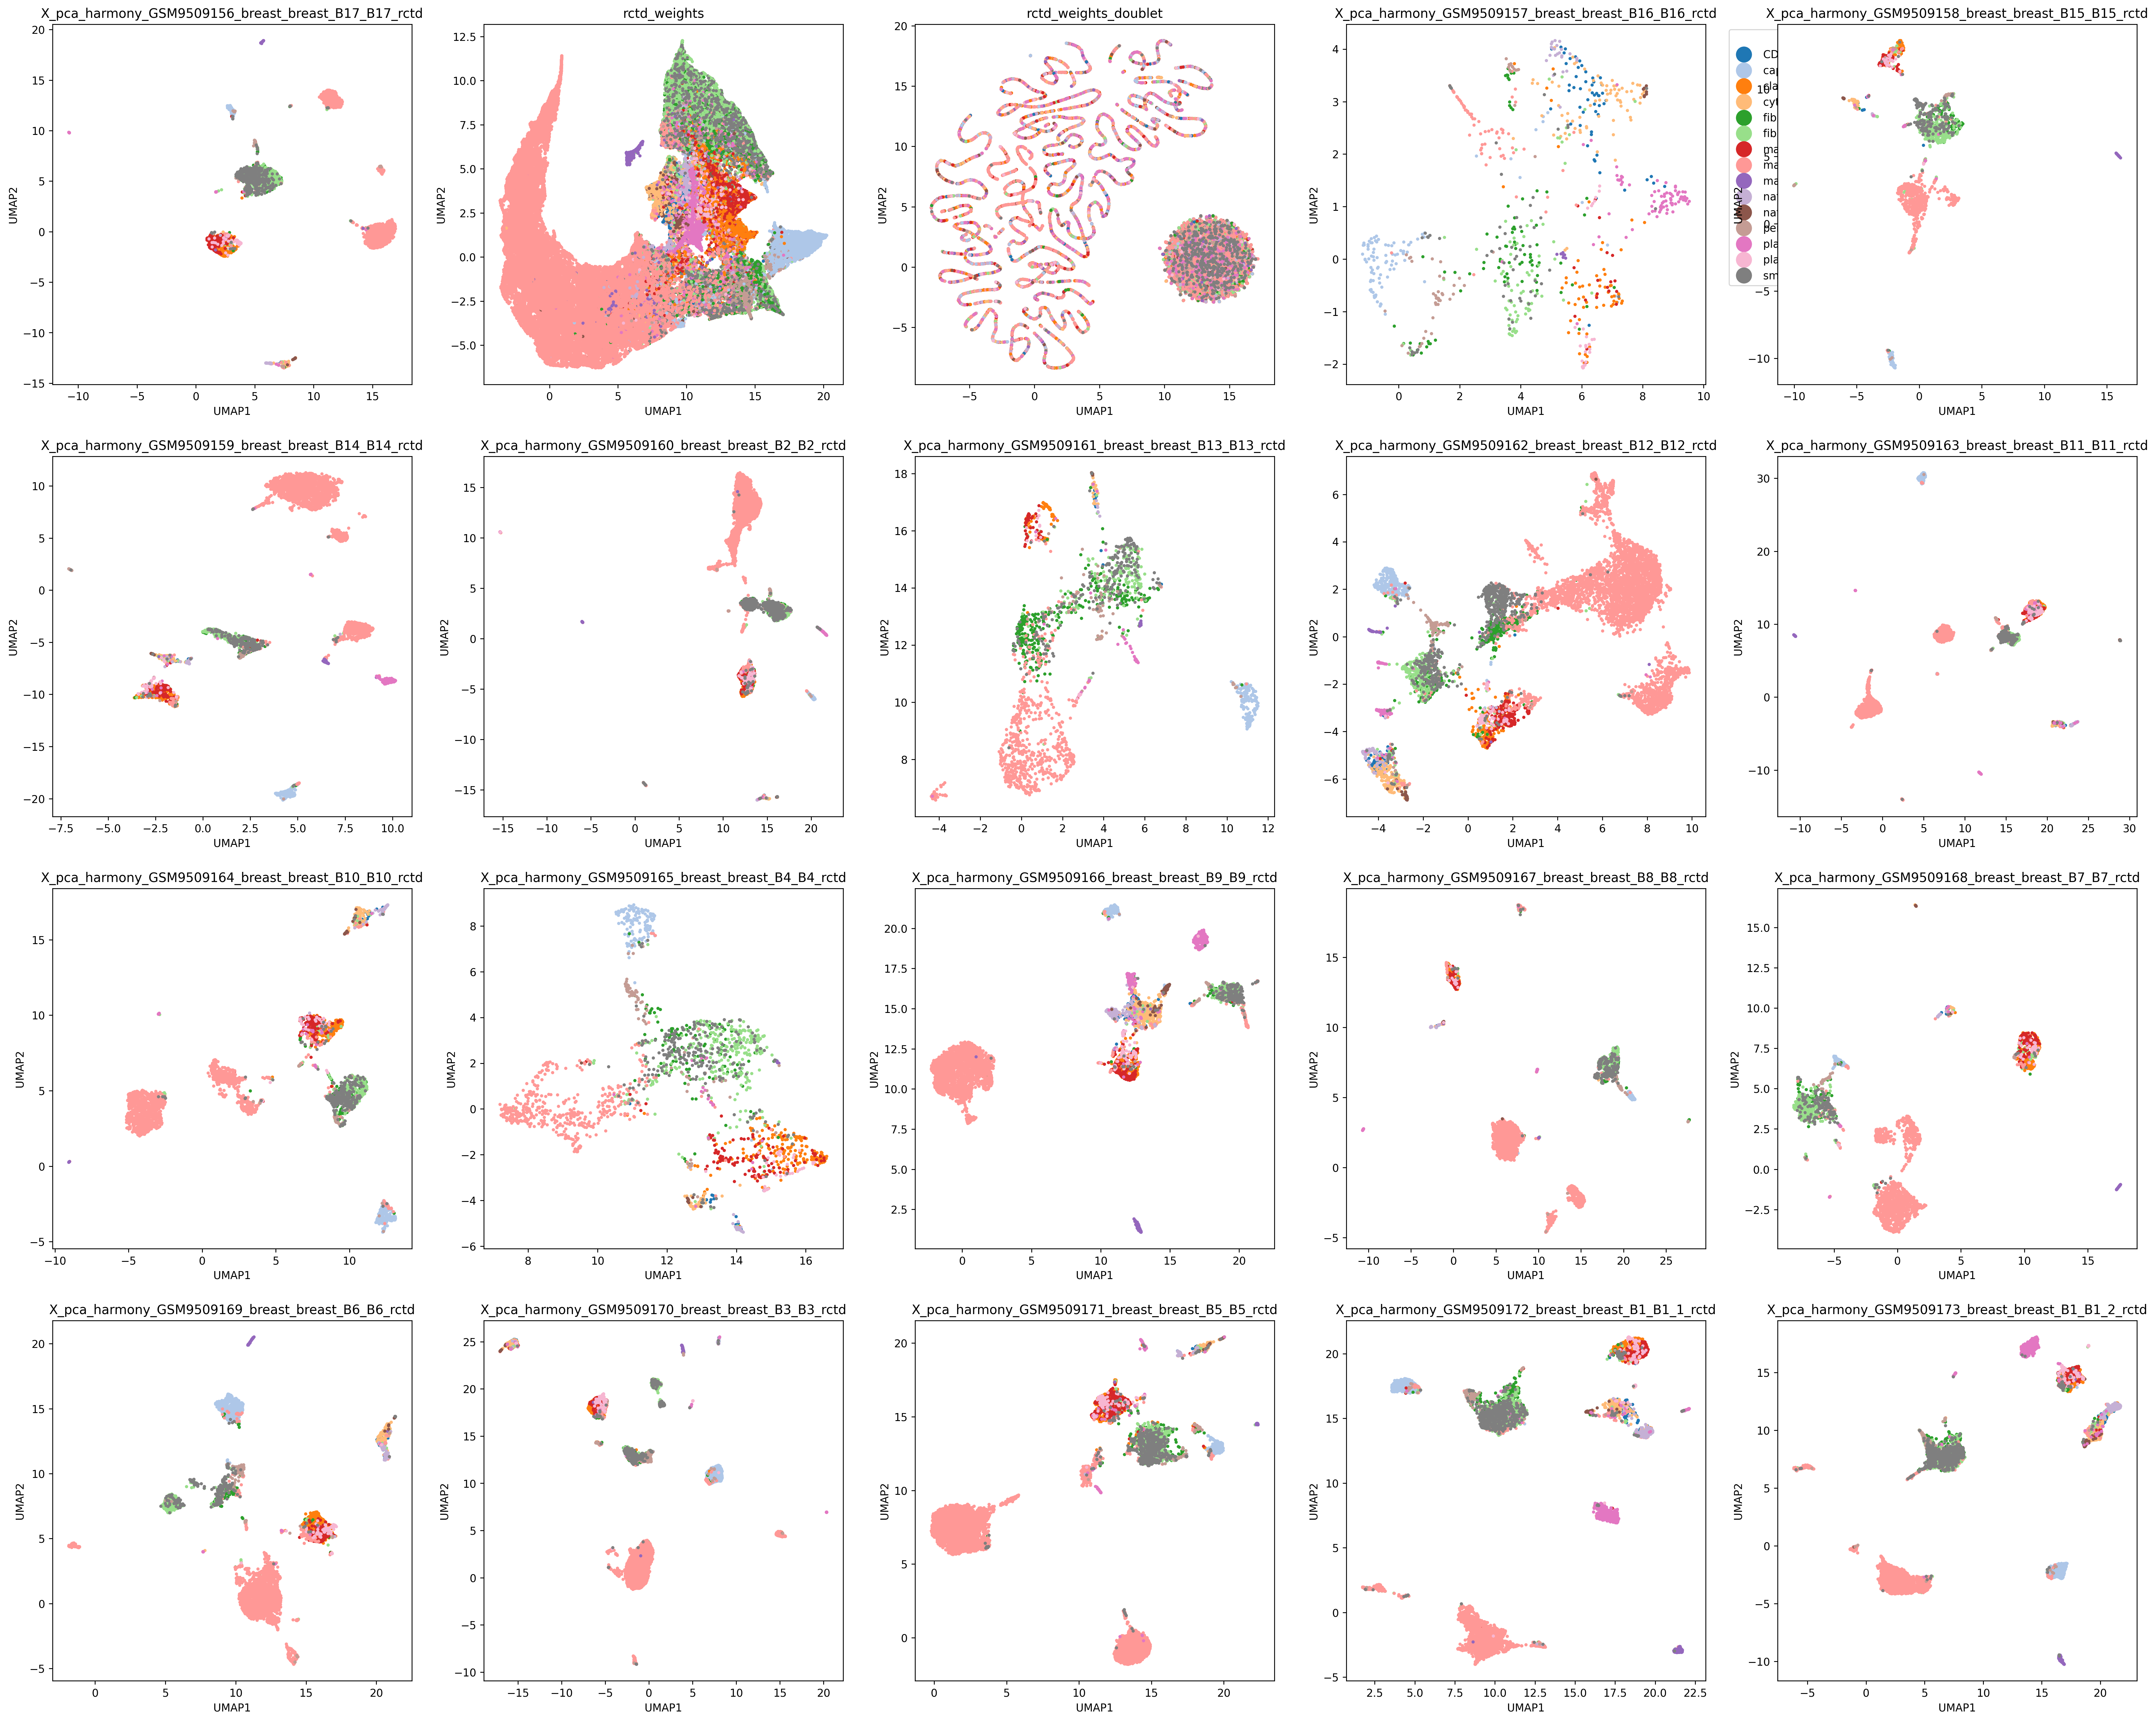

In [ ]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

settings = list(metrics_adata.obsm.keys())[1:]

# All tissues are included in each UMAP.
tissue_subset = metrics_adata.obs["source_file"].dropna().unique().tolist()

cell_types = sorted(metrics_adata.obs["harmony_cell_type"].astype(str).dropna().unique())
cell_type_palette = dict(zip(cell_types, sns.color_palette("tab20", n_colors=len(cell_types))))

plot_data = {}

for setting in settings:
    mask = (
        (np.sum(np.isnan(metrics_adata.obsm[setting]), axis=1) == 0)
        & metrics_adata.obs["source_file"].isin(tissue_subset).to_numpy()
    )

    set_adata = metrics_adata[mask].copy()
    coords = UMAP().fit_transform(set_adata.obsm[setting])

    plot_data[setting] = {
        "adata": set_adata,
        "coords": coords,
    }


def plot_umap_panels(color_by="harmony_cell_type", palette=None):
    fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(35, 28), dpi=250)

    for i, setting in enumerate(settings):
        ax = axes.flat[i]
        set_adata = plot_data[setting]["adata"]
        coords = plot_data[setting]["coords"]

        legend = i == 3

        sns.scatterplot(
            x=coords[:, 0],
            y=coords[:, 1],
            hue=set_adata.obs[color_by].astype(str),
            s=9,
            ax=ax,
            legend=legend,
            palette=palette,
            linewidth=0,
            rasterized=True,
        )

        ax.set_title(setting)
        ax.set_xlabel("UMAP1")
        ax.set_ylabel("UMAP2")

        if legend:
            ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", markerscale=5, title=color_by)

    fig.tight_layout()
    return fig, axes

# fig_cell_type, axes_cell_type = plot_umap_panels(
#     color_by="Major cell type",
#     palette="tab20",
#     highlight_neutrophils=False,
# )

fig_tissue, axes_tissue = plot_umap_panels(
    color_by="harmony_cell_type",
    palette="tab20",
    # highlight_neutrophils=False,
)

# fig_tissue, axes_tissue = plot_umap_panels(
#     color_by="harmony_spatial_tissue",
#     highlight_neutrophils=False,
# )

IndexError: index 8 is out of bounds for axis 0 with size 8

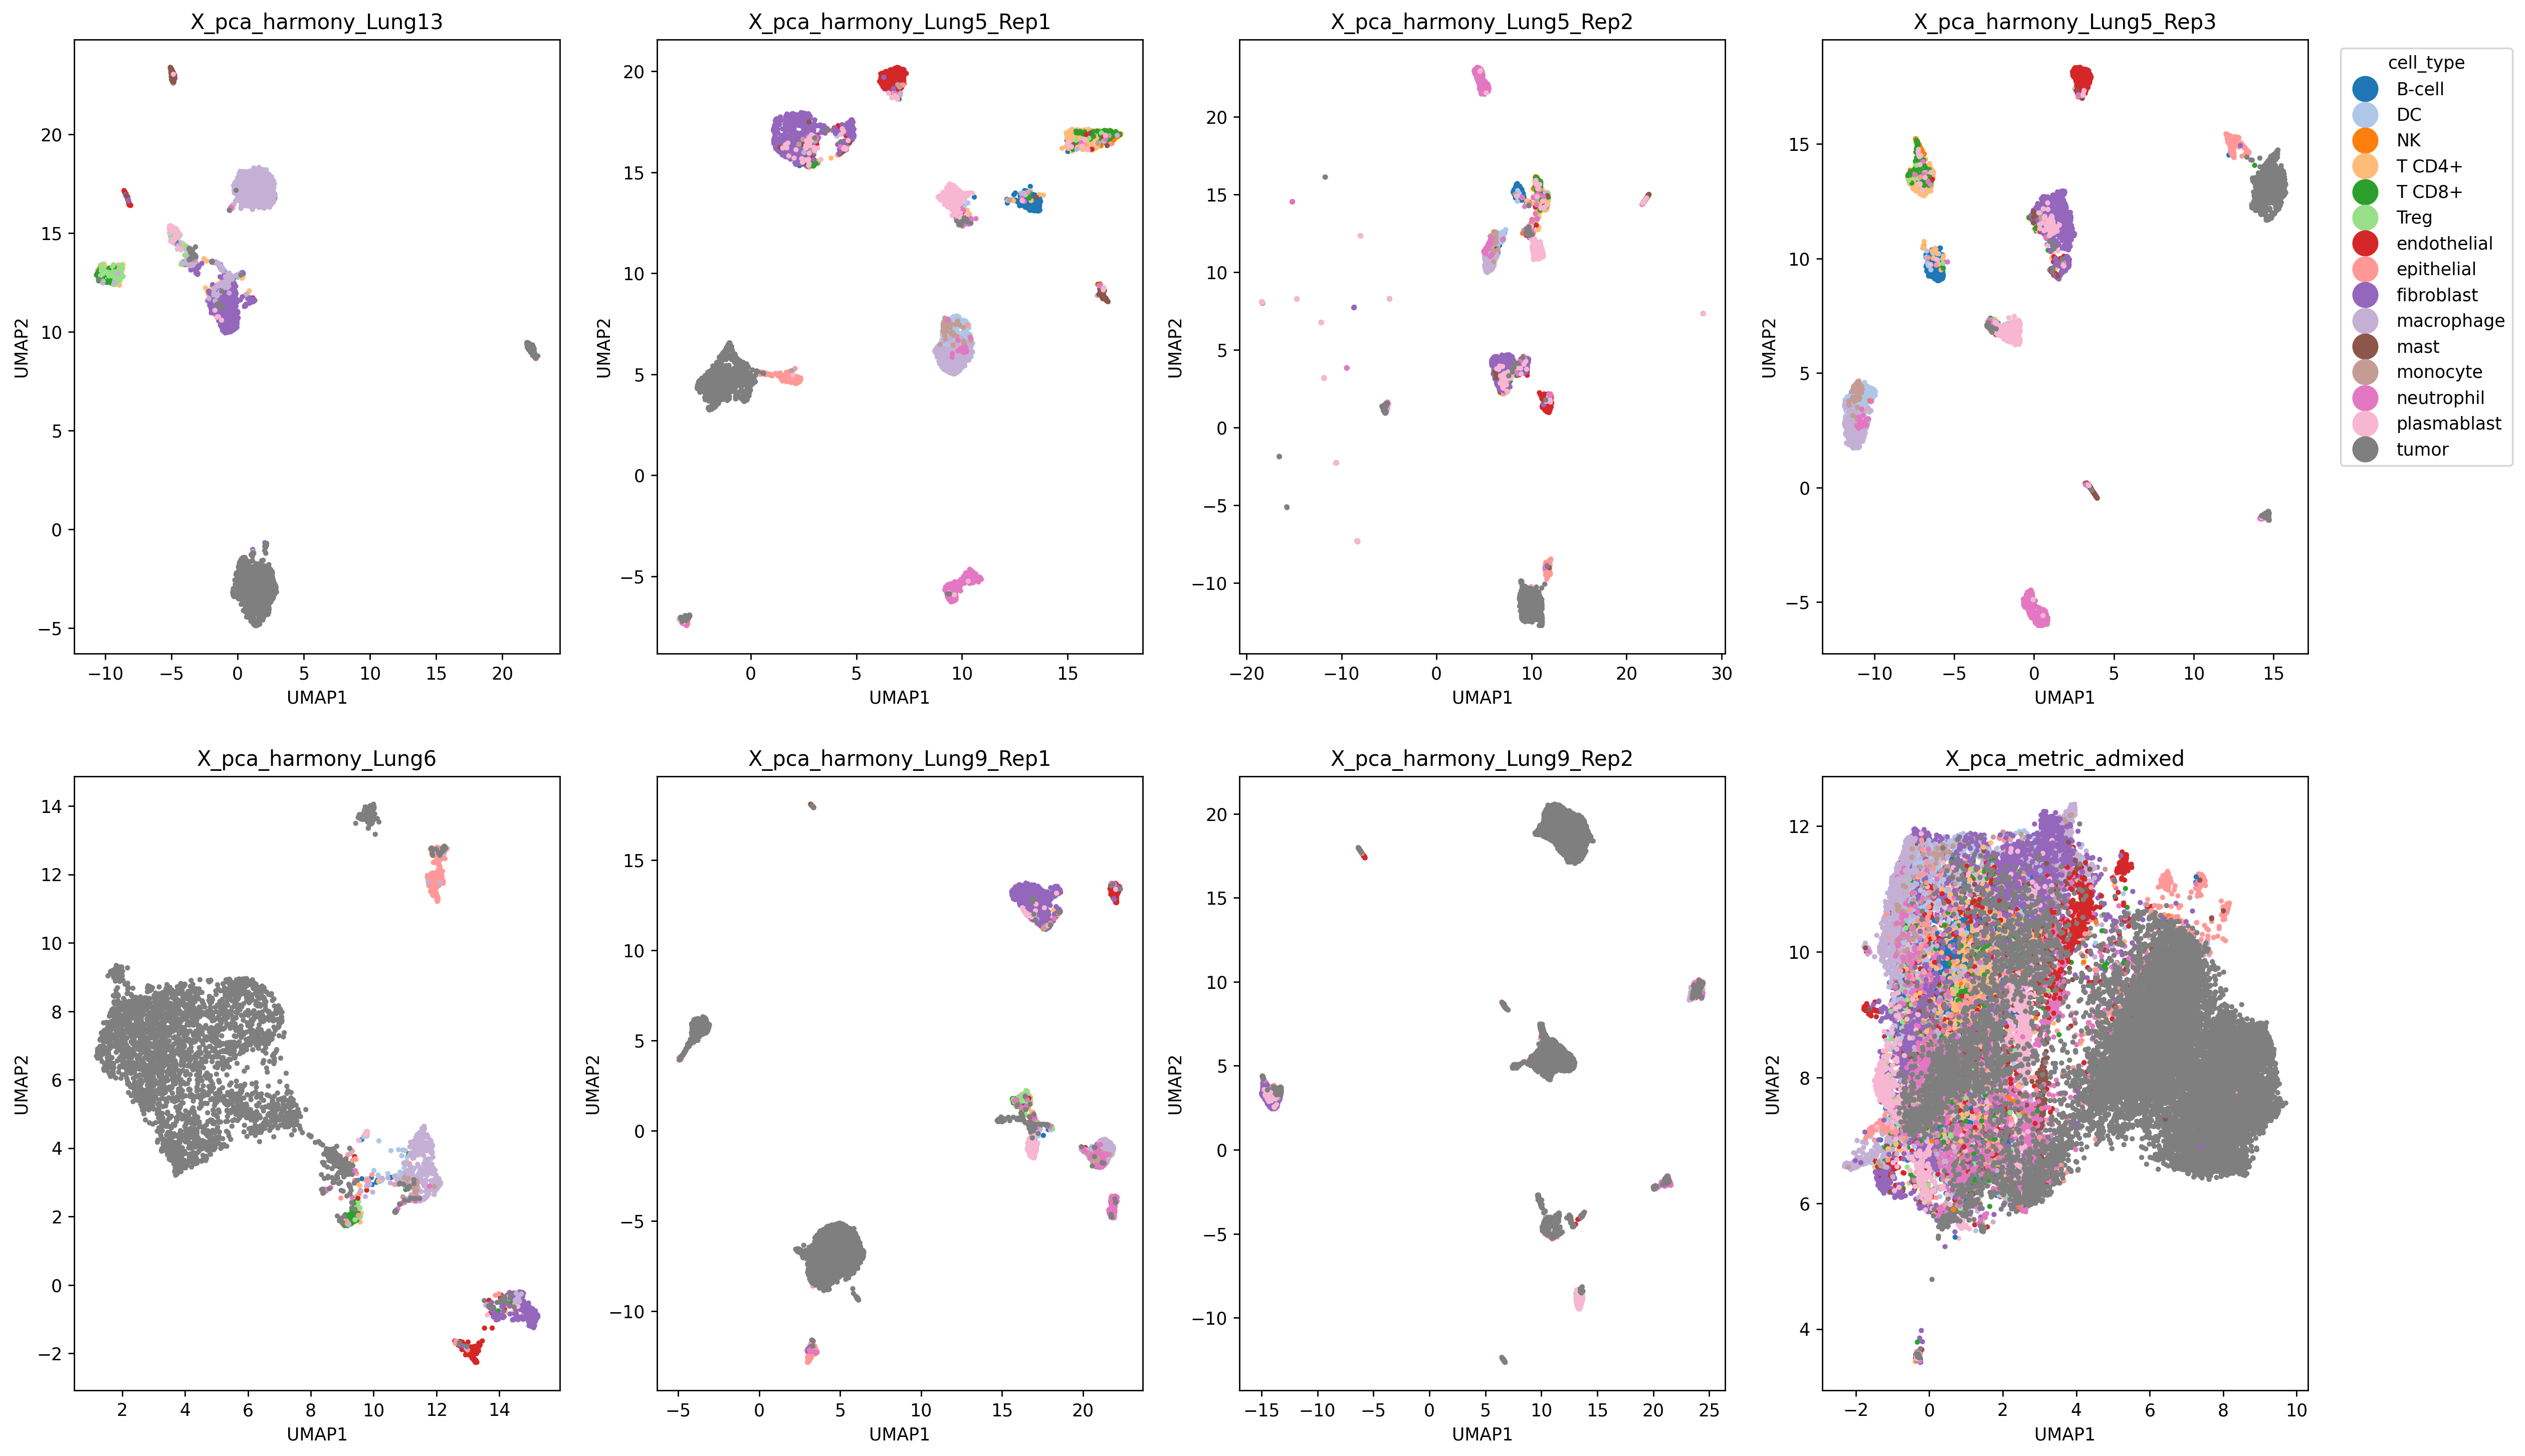

In [ ]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

settings = list(metrics_adata.obsm.keys())[1:]

cell_types = sorted(metrics_adata.obs["cell_type"].astype(str).dropna().unique())
cell_type_palette = dict(zip(cell_types, sns.color_palette("tab20", n_colors=len(cell_types))))

plot_data = {}

for setting in settings:
    mask = np.sum(np.isnan(metrics_adata.obsm[setting]), axis=1) == 0

    set_adata = metrics_adata[mask].copy()
    coords = UMAP().fit_transform(set_adata.obsm[setting])

    plot_data[setting] = {
        "adata": set_adata,
        "coords": coords,
    }


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(23, 14), dpi=250)

for i, setting in enumerate(settings):
    ax = axes.flat[i]
    set_adata = plot_data[setting]["adata"]
    coords = plot_data[setting]["coords"]

    sns.scatterplot(
        x=coords[:, 0],
        y=coords[:, 1],
        hue=set_adata.obs["cell_type"].astype(str),
        palette=cell_type_palette,
        s=9,
        ax=ax,
        legend=(i == 3),
        linewidth=0,
        rasterized=True,
    )

    ax.set_title(setting)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")

    if i == 3:
        ax.legend(
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            markerscale=5,
            title="cell_type",
        )

fig.tight_layout()

In [ ]:
plot_data

{'X_pca_harmony_Lung13': {'adata': View of AnnData object with n_obs × n_vars = 403 × 958
      obs: 'fov', 'cell_ID', 'tissue', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'sdimx', 'sdimy', 'cell_ID_long', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.CD298', 'Max.CD298', 'Mean.G', 'Max.G', 'Mean.Y', 'Max.Y', 'Mean.R', 'Max.R', 'Mean.DAPI', 'Max.DAPI', 'dualfiles', 'Slide_name', 'Run_name', 'ISH.concentration', 'Dash', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity', 'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells', 'patient', 'cell_type_orig', 'niche', 'prop_tumor_in_100_neighbors', 'cell_type', 'batch', 'split'
      uns: 'cell_type_separation_metrics'
      obsm: 'X_pca_harmony_Lung12', 'X_pca_harmony_Lung13', 'X_pca_harmony_Lung5_Rep1', 'X_pca_harmony_Lung5_Rep2', 'X_pca_harmony_Lung5_Rep3', 'X_pca_harmony_Lung6', 'X_pca_harmony_Lung9_Rep1', 'X_pca_harmony_Lung9_Rep2', 'X_pca_metric_admixed', 'X_pca_metric_

In [ ]:
metrics_adata.layers

In [ ]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
counts=metrics_adata.layers['admixed_counts'].toarray().flatten()
probs=probs[probs>0]
counts=counts[counts>10]

ax = sns.histplot(counts,bins=1000)
ax.set_title('Admix Probabilities (for probs > 0)')

In [ ]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
raw_counts=metrics_adata.X.toarray().flatten()
admix_counts = metrics_adata.layers['admixed_counts'].toarray().flatten()

nonadmix_probs=probs[(admix_counts==0)&(raw_counts>0)]
admix_probs=probs[(admix_counts>0)]
fig,ax = plt.subplots(figsize=(7,5))

ax = sns.histplot(nonadmix_probs,bins=100,ax=ax,label='non-admixed')
ax = sns.histplot(admix_probs,bins=100,ax=ax,label='admixed')
ax.set_ylim([0,100000])
ax.set_title('Admix Probabilities')
ax.legend()

In [ ]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
raw_counts=metrics_adata.X.toarray().flatten()
admix_counts = metrics_adata.layers['admixed_counts'].toarray().flatten()
counts = raw_counts+admix_counts
nonadmix_probs=probs[(admix_counts==0)&(raw_counts>0)]
admix_probs=probs[(admix_counts>0)]

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax = sns.scatterplot(x=nonadmix_probs,y=counts[(admix_counts==0)&(raw_counts>0)],label='non-admixed',ax=ax,s=3,alpha=0.2)
ax = sns.scatterplot(x=admix_probs,y=counts[admix_counts>0],label='admixed',ax=ax,s=3,alpha=0.2)

ax.set_title("Gene Admixture Probability vs Number of Transcripts Added")
ax.set_xlabel("admix prob")
ax.set_ylabel("transcript count")
ax.legend()